# 02 Baseline Model - DummyClassifier

This notebook implements and evaluates a DummyClassifier baseline for binary sentiment classification.
The baseline establishes the "no-skill" floor that our neural models must exceed.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    cohen_kappa_score, confusion_matrix, classification_report
)
import sys
import os

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)

print(" Libraries imported successfully")

 Libraries imported successfully


In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
test_df = pd.read_csv('../data/processed/test.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

X_train_raw = train_df['cleaned_text']
y_train = train_df['sentiment']
X_test_raw = test_df['cleaned_text']
y_test = test_df['sentiment']

y_train = y_train.map({'negative': 0, 'positive': 1})
y_test = y_test.map({'negative': 0, 'positive': 1})

tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_train = tfidf.fit_transform(X_train_raw)
X_test = tfidf.transform(X_test_raw)

print(" Data loaded and vectorized")

Train shape: (800, 7)
Test shape: (200, 7)
 Data loaded and vectorized


In [3]:
dummy_mf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_strat = DummyClassifier(strategy='stratified', random_state=42)

dummy_mf.fit(X_train, y_train)
dummy_strat.fit(X_train, y_train)

print(" Models trained")

 Models trained


In [4]:
results = []

for name, model in [('Most Frequent', dummy_mf), ('Stratified', dummy_strat)]:
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    kappa = cohen_kappa_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Cohens_Kappa': round(kappa, 4)
    })
    
    print(f"\n--- {name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Kappa:     {kappa:.4f}")

results_df = pd.DataFrame(results)
os.makedirs('../outputs/metrics', exist_ok=True)
results_df.to_csv('../outputs/metrics/baseline_metrics.csv', index=False)
print("\n Metrics saved to outputs/metrics/baseline_metrics.csv")


--- Most Frequent ---
Accuracy:  0.5000
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
Kappa:     0.0000

--- Stratified ---
Accuracy:  0.5000
Precision: 0.5000
Recall:    0.5100
F1-Score:  0.5050
Kappa:     0.0000

 Metrics saved to outputs/metrics/baseline_metrics.csv


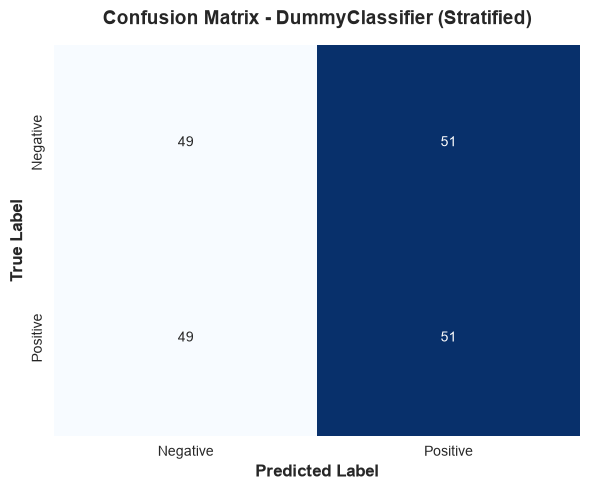


 Confusion matrix saved to outputs/figures/confusion_matrix_baseline.png


In [5]:
y_pred_strat = dummy_strat.predict(X_test)
cm = confusion_matrix(y_test, y_pred_strat)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Positive'], 
            yticklabels=['Negative', 'Positive'],
            ax=ax, cbar=False)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix - DummyClassifier (Stratified)', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
os.makedirs('../outputs/figures', exist_ok=True)
plt.savefig('../outputs/figures/confusion_matrix_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Confusion matrix saved to outputs/figures/confusion_matrix_baseline.png")